# Material de aula - FACENS - Aprendizado de Máquina


## Regressão Linear - Laboratório 00

In [1]:
#CÉLULA LINREG-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline
import seaborn as sns

In [2]:
def gera_dados() :
    '''
    Gera um conjunto de dados aleatório com distribuição não-linear
    '''
    X = np.random.uniform(size=100)
    Y = np.log(X/(1-X))
    Y = np.sign(Y)*np.abs(Y)**1.4
    
    return (X,Y)

# 1 - Regressão Linear Simples

## 1.1 - Calcule o coeficiente de correlação de Pearson utilizando a matriz de covariância

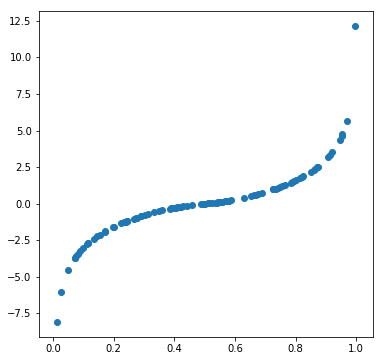

In [3]:
#Plote os dados gerados pela função
X,Y = gera_dados()

#Gera o gráfico dos dados
plt.figure( figsize=(6,6))
plt.scatter(X,Y)
plt.show()

In [4]:
cc = np.cov(X,Y)
cc
c = cc[0,1]/np.sqrt(cc[0,0]*cc[1,1])
c

0.8839408889568786

## 1.2 - Importe as funções de pearson e spearman da biblioteca scipy

In [5]:
from scipy.stats import pearsonr
from scipy.stats import spearmanr

## 1.3 - Calcule o coeficiente de correlação de Pearson utilizando as funções da scipy

In [6]:
#Pearson
pearsonr(X,Y)

(0.8839408889568785, 4.028727556348065e-34)

In [7]:
#Spearman
spearmanr(X, Y)

SpearmanrResult(correlation=0.9999999999999999, pvalue=0.0)

## 1.4 - Exemplo: Vendas de sorvete em função da temperatura

In [8]:
x = np.array([10,15,20])
y = np.array([40,75,85])

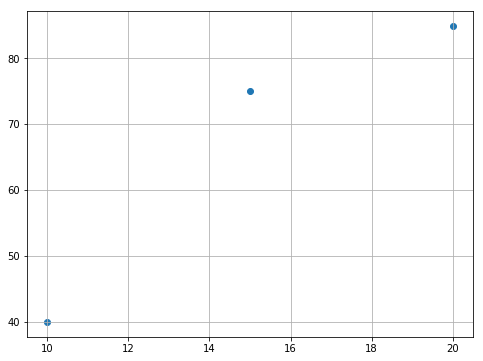

In [9]:
plt.figure(figsize=(8,6))
plt.grid()
plt.scatter(x,y)

In [10]:
pearsonr(x,y)

(0.9522165814091077, 0.19759612400303037)

In [11]:
spearmanr(x,y)

SpearmanrResult(correlation=1.0, pvalue=0.0)

## 1.5 - Calcule os coeficientes de regressão linear

In [12]:
bar_x = np.mean(x)
bar_y = np.mean(y)

a =  sum((x - bar_x)*(y - bar_y)) / sum((x - bar_x)**2)
b = bar_y - a * bar_x

In [13]:
print('[{}] - [{}]'.format(a,b))

[4.5] - [-0.8333333333333286]


In [14]:
yp = a*x+b #erro quadrático
yp #y previsto

n=len(x)
p=2
MSE = sum((y - yp)**2) / (n-p)
MSE

104.16666666666666

## 1.6 - Calcule o coeficiente de determinação

In [15]:
rr = pearsonr(x,y)[0] ** 2
rr

0.9067164179104479

## 1.7 - Repita os cálculos usando o modelo de regressão linear da scikit learn

In [16]:
#Usando scikit
from sklearn.linear_model import LinearRegression
lm = LinearRegression() #estancia

In [17]:
x= x.reshape((3,1))
y= y.reshape((3,1))

In [18]:
lm.fit(x,y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

In [19]:
print('Coefficients: \n', lm.coef_)

Coefficients: 
 [[4.5]]


In [20]:
#Coeficiente de determinação
lm.score(x,y)

0.9067164179104478

## Exemplo 2: Considere um experimento em que se analisa a octanagem da gasolina (Y) em função da adição de um aditivo (X). Para isto, foram realizados ensaios com os percentuais de 1, 2, 3, 4, 5 e 6% de aditivo.  Os resultados estão na tabela abaixo:

|     x       |      y      |
|-------------|-------------|
|     1       |    80,5     |
|     2       |    81,6     |
|     3       |    82,1     |
|     4       |    83,7     |
|     5       |    83,9     |
|     6       |    85,5     |

## Faça as seguintes atividades:

1. Plote o gráfico dos dados
2. Calcule o coeficiente de correlação
3. Calcule os parâmetros de Regressão Linear
4. Calcule o coeficiente de determinação $R^2$

In [21]:
x = np.array([1,2,3,4,5,6])
y = np.array([80.5, 81.6, 82.1, 83.7, 83.9, 85])

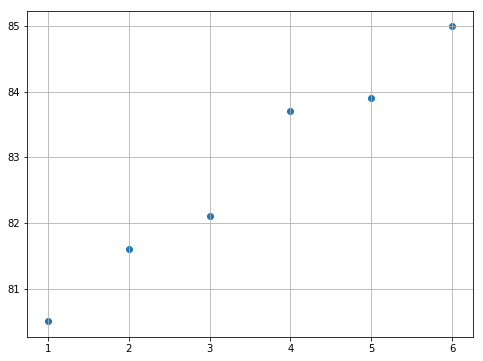

In [22]:
plt.figure(figsize=(8,6))
plt.grid()
plt.scatter(x,y)

In [23]:
pearsonr(x,y)

(0.9874414334103995, 0.00023558603871991373)

In [24]:
spearmanr(x,y)

SpearmanrResult(correlation=1.0, pvalue=0.0)

## 2.1 - Calcule os coeficientes de regressão linear

In [25]:
bar_x = np.mean(x)
bar_y = np.mean(y)

a =  sum((x - bar_x)*(y - bar_y)) / sum((x - bar_x)**2)
b = bar_y - a * bar_x

In [26]:
print('[{}] - [{}]'.format(a,b))

[0.8857142857142869] - [79.69999999999999]


In [27]:
yp = a*x+b
yp

n=len(x)
p=2
MSE = sum((y - yp)**2) / (n-p)
MSE

0.08785714285714322

## 2.2 - Calcule o coeficiente de determinação

In [28]:
rr = pearsonr(x,y)[0] ** 2
rr

0.9750405844155844

## 2.3 - Agora repita o cálculo usando a scikit learn

In [29]:
#Usando scikit
from sklearn.linear_model import LinearRegression
lm = LinearRegression()

In [30]:
x= x.reshape((len(x),1))
y= y.reshape((len(y),1))

In [31]:
lm.fit(x,y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

In [32]:
print('Coefficients: \n', lm.coef_)

Coefficients: 
 [[0.88571429]]


In [33]:
#Coeficiente de determinação
lm.score(x,y)

0.9750405844155844

# 3 - Exemplo: Regressão multivariável

In [54]:
dfDataFile = pd.read_csv('kc_house_data.csv')
#dfDataFile.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [55]:
dfDataFile.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [36]:
dfDataFile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
id               21613 non-null int64
date             21613 non-null object
price            21613 non-null float64
bedrooms         21613 non-null int64
bathrooms        21613 non-null float64
sqft_living      21613 non-null int64
sqft_lot         21613 non-null int64
floors           21613 non-null float64
waterfront       21613 non-null int64
view             21613 non-null int64
condition        21613 non-null int64
grade            21613 non-null int64
sqft_above       21613 non-null int64
sqft_basement    21613 non-null int64
yr_built         21613 non-null int64
yr_renovated     21613 non-null int64
zipcode          21613 non-null int64
lat              21613 non-null float64
long             21613 non-null float64
sqft_living15    21613 non-null int64
sqft_lot15       21613 non-null int64
dtypes: float64(5), int64(15), object(1)
memory usage: 3.5+ MB


In [37]:
#Alguns campos nao muito uteis
dfDataFile.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [38]:
#Campos nao muito uteis: 'id'
dfDataFile.drop(['id'], axis=1, inplace=True)

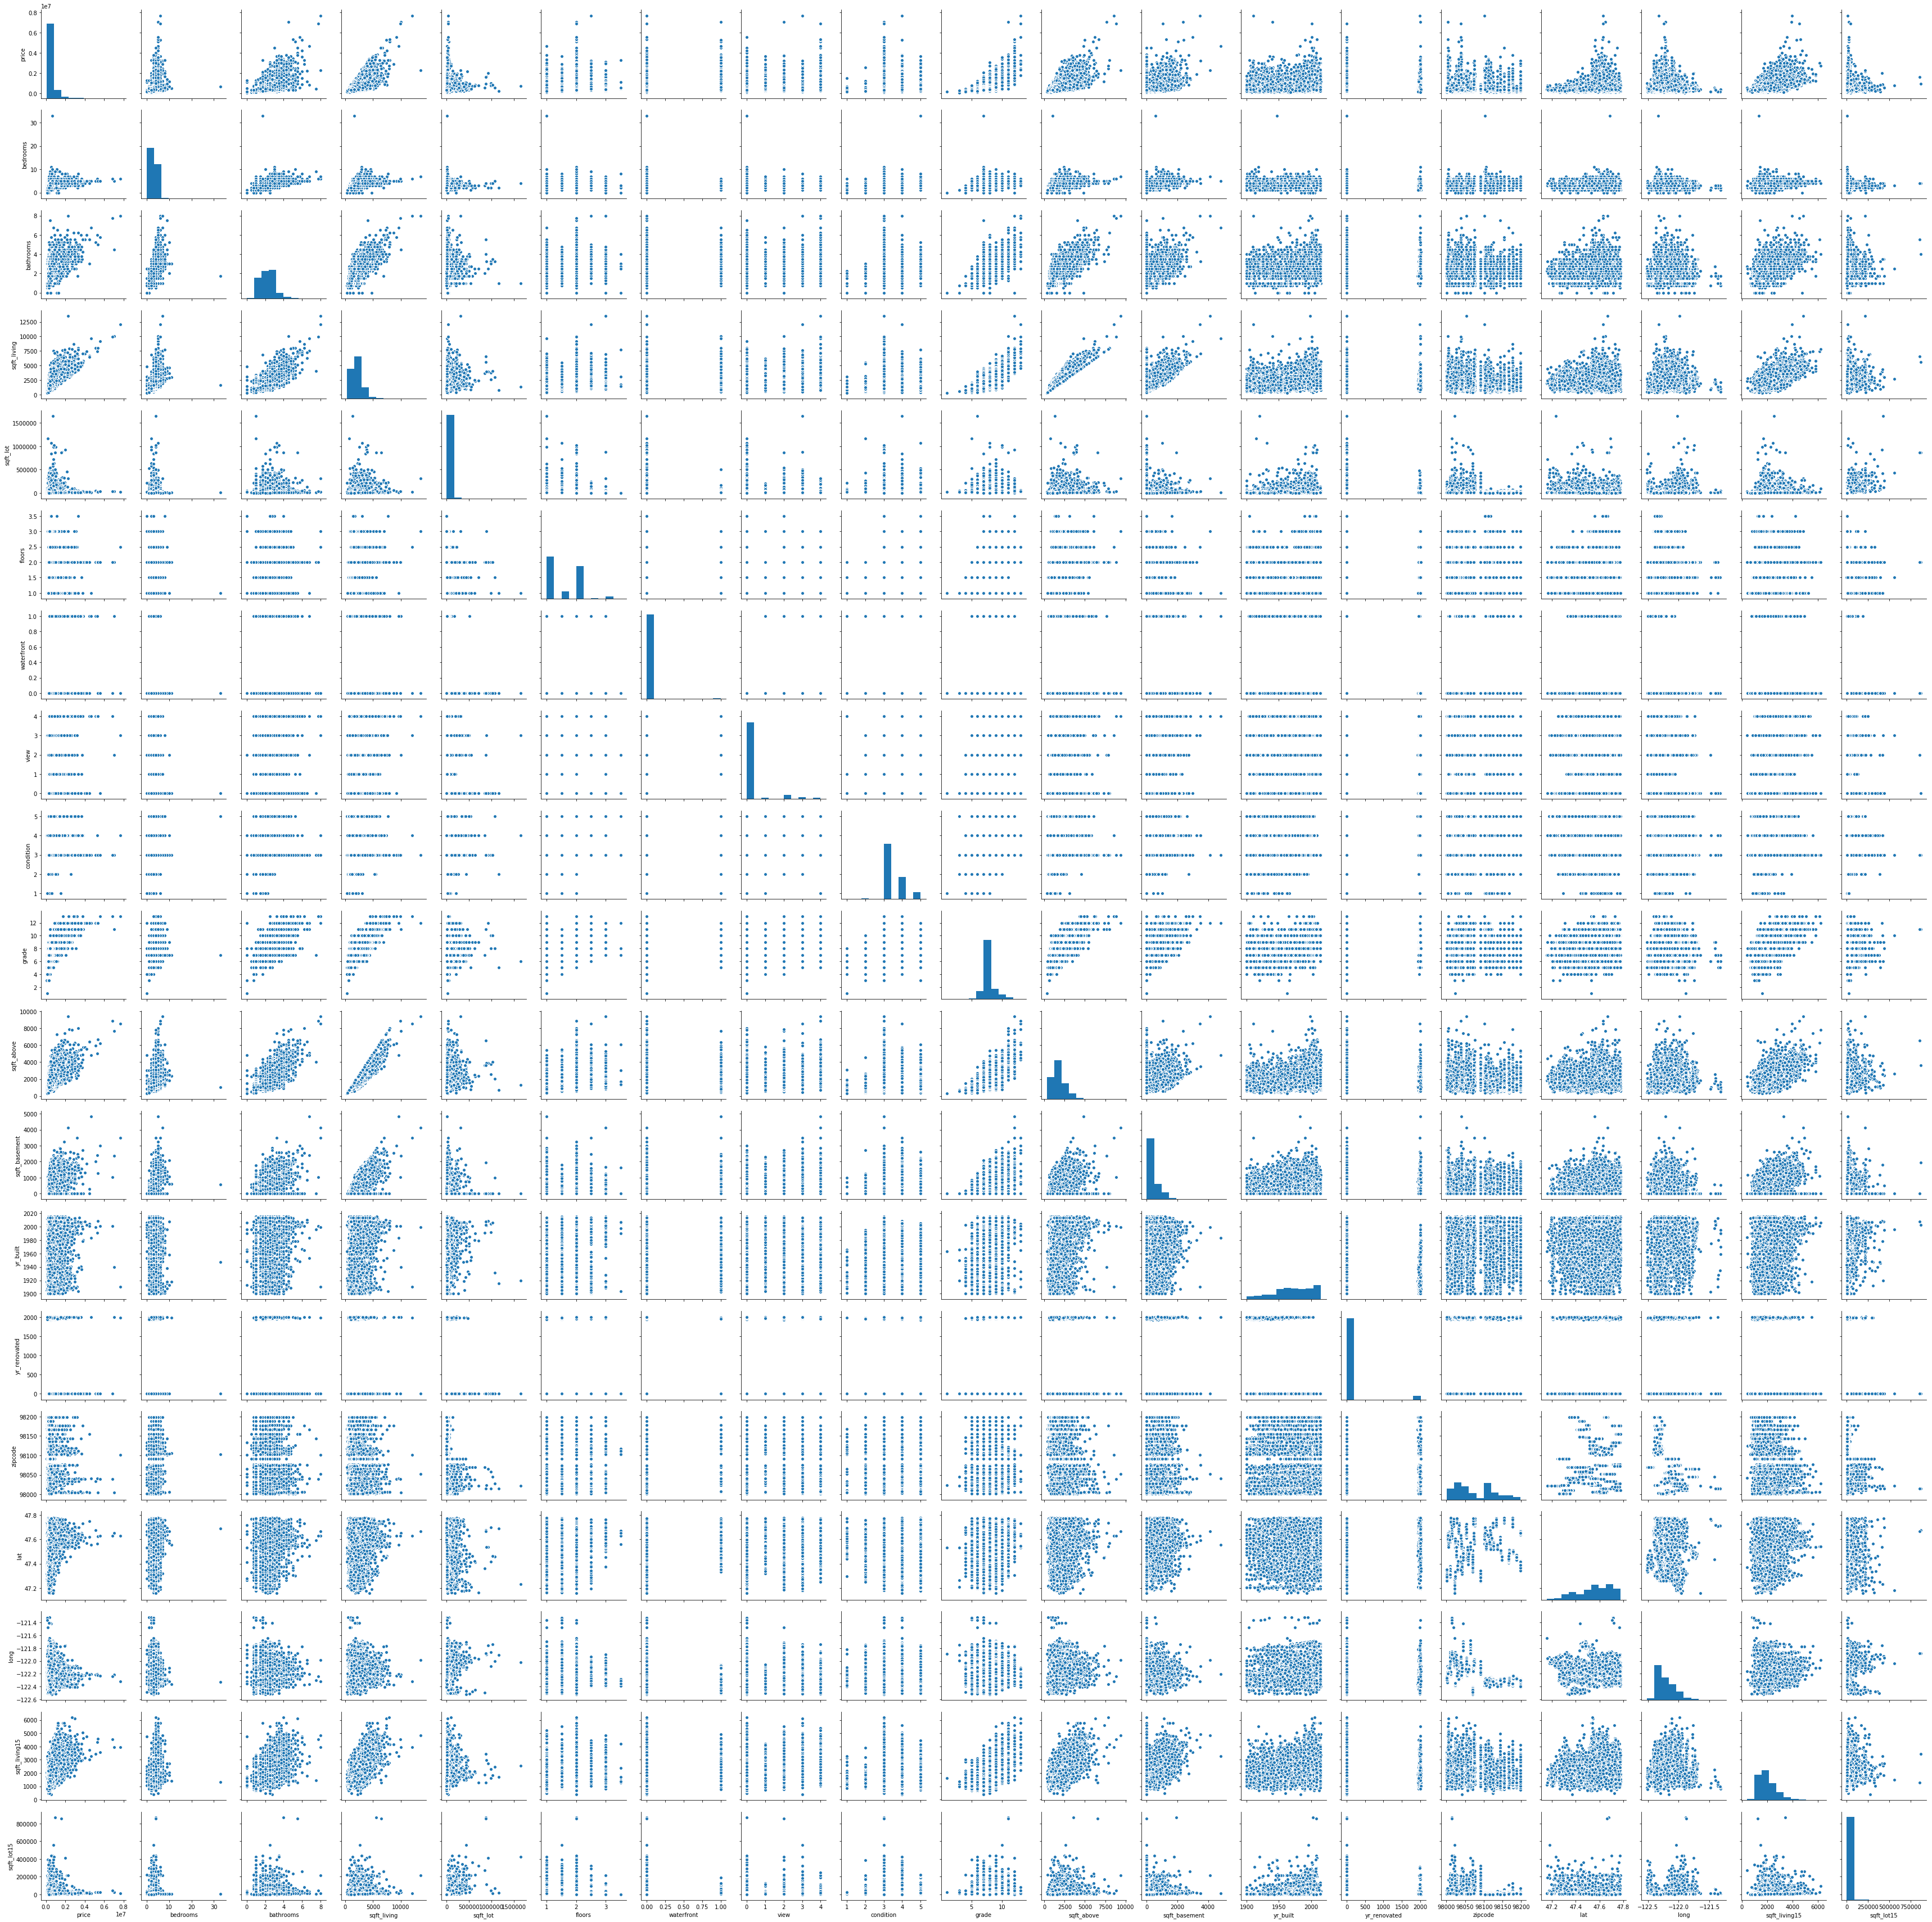

In [39]:
sns.pairplot(dfDataFile)

In [40]:
#Colunas que podemos remover, a principio: 0,2,5,6,7,8,9,12,13,14,15,17,19
#Podemos remover tb a coluna 'date' e depois separar a 'price' para treinamento e teste
dfDataFile.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [41]:
dfFilteredData = dfDataFile.drop(['date', 'bedrooms', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'long', 'sqft_lot15'], axis=1)

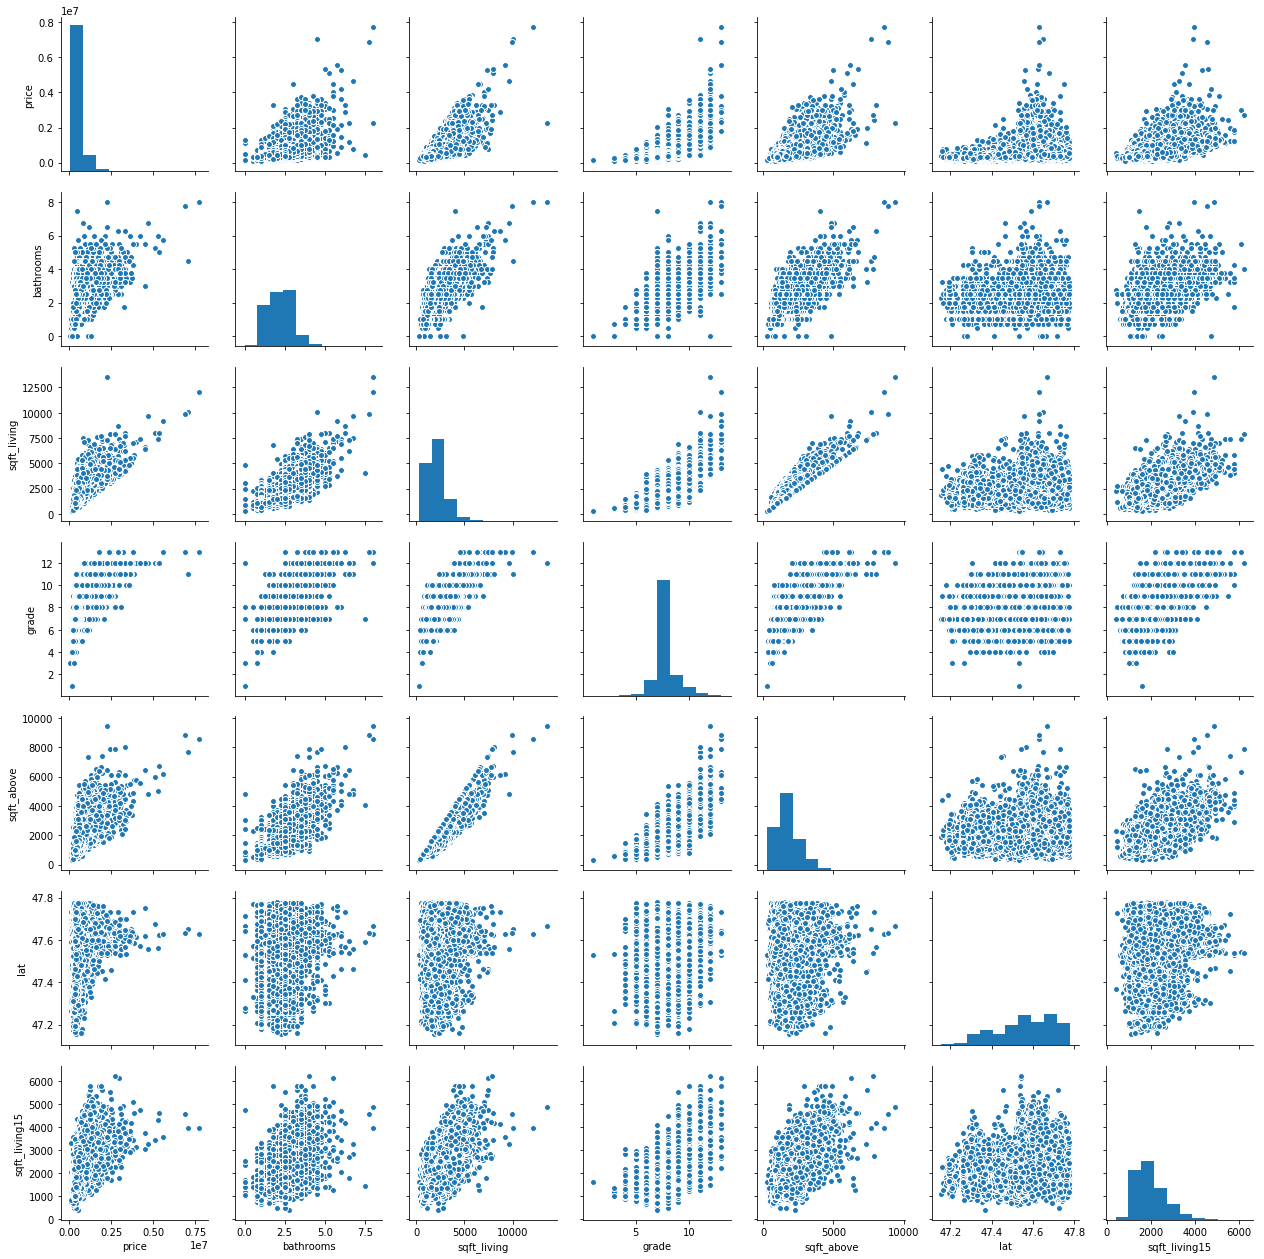

In [42]:
sns.pairplot(dfFilteredData)

In [43]:
x = dfFilteredData.copy()
x.drop(['price'], axis=1, inplace=True) #x não tem os preços
y = dfFilteredData['price']

In [44]:
from sklearn.cross_validation import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 0)

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cross_validation.py:41: DeprecationWarning: This module was deprecated in version 0.18 in favor of the model_selection module into which all the refactored classes and functions are moved. Also note that the interface of the new CV iterators are different from that of this module. This module will be removed in 0.20.
  "This module will be removed in 0.20.", DeprecationWarning)


In [45]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()

In [46]:
lm.fit(X_train,y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

In [47]:
print('Coefficients: \n', lm.coef_)

Coefficients: 
 [-2.86022437e+04  2.34966429e+02  8.84928580e+04 -4.72297137e+01
  6.44583689e+05  2.39364139e+01]


## Previsão de dados- teste

In [48]:
predictions = lm.predict( X_test )

Text(0,0.5,'Predicted Y')

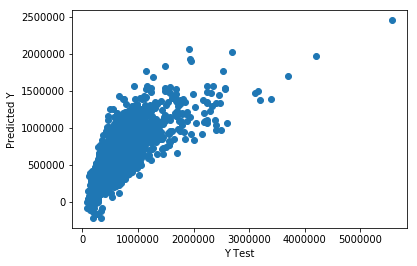

In [49]:
plt.scatter(y_test,predictions)
plt.xlabel('Y Test')
plt.ylabel('Predicted Y')

In [50]:
from sklearn import metrics

print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

MAE: 139998.662223425
MSE: 46193501668.26414
RMSE: 214926.73558276583


C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


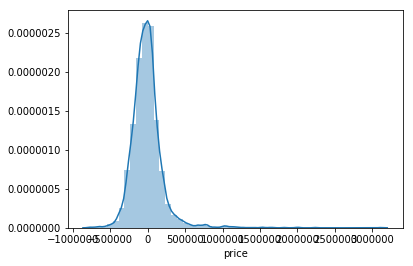

In [51]:
sns.distplot((y_test-predictions),bins=50);

In [52]:
lm.score(X_test, y_test)

0.6115721211367082

In [53]:
coefficients = pd.DataFrame(lm.coef_,x.columns)
coefficients.columns = ['Coefficient']
coefficients

,Coefficient
bathrooms,-28602.243699
sqft_living,234.966429
grade,88492.858000
sqft_above,-47.229714
lat,644583.688810
sqft_living15,23.936414
